[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L5/BA_L5_tar/BA_L5_tar.ipynb)

# BA_L5_tar: A Threshold Autoregression for the Arbitrage Band

*Quantlet of Lecture 5, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Threshold autoregression (TAR) of the hourly change of USDC priced in USDT on its lagged deviation, January 2022 to 23 October 2026: band estimated by least squares, heteroskedasticity-consistent Wald profile and the Hansen (1996) fixed-regressor bootstrap of sup W. Data: EODHD hourly prices.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

Setup: chart style and colours of the slides, and a `save()` helper that puts one legend below the figure.

In [4]:
import matplotlib
import matplotlib.dates as mdates
from scipy import stats

# the slide charts use matplotlib's default sizes with 10-point text and an 8-point legend
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 'medium', 'axes.titlesize': 'large', 'axes.linewidth': 0.8,
                     'lines.linewidth': 1.5, 'legend.fontsize': 8})
COL = {'USDT': GREEN, 'USDC': BLUE, 'DAI': GOLD}


def save(fig, name, bottom, ncol=3):
    """One legend for all panels below the plot (as on the slide), then save to OUT_PATH and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

## What the chart shows

If arbitrage costs $c$, small deviations are not worth trading and large ones are. A threshold autoregressive (TAR) model for the deviation $d_t$ of USDC priced in USDT, in basis points (bp), captures this:

$$ \Delta d_t = \mu + \rho_{in}\, d_{t-1}\,\mathbb 1\{|d_{t-1}| \leq \gamma\} + \rho_{out}\, d_{t-1}\,\mathbb 1\{|d_{t-1}| > \gamma\} + \varepsilon_t . $$

The band hypothesis is $\rho_{in} \approx 0$ and $\rho_{out} < 0$; the half-life of a deviation is $h = \ln 0.5 / \ln(1 + \rho)$ hours.

- Estimation: ordinary least squares (OLS) for each $\gamma$ on a grid (the 70% to 99.5% quantiles of $|d_{t-1}|$); $\hat\gamma$ minimises the sum of squared residuals.
- Test of $H_0: \rho_{in} = \rho_{out}$ with a heteroskedasticity-consistent (HC) variance:
$$ \sup W = \sup_{\gamma} W(\gamma), \qquad W(\gamma) = \frac{(\hat\rho_{in} - \hat\rho_{out})^2}{\widehat{\mathrm{Var}}_{\mathrm{HC}}(\hat\rho_{in} - \hat\rho_{out})} . $$
- Under $H_0$ the threshold is not identified, so the $\chi^2$ distribution does not apply; the p-value comes from the fixed-regressor bootstrap of [Hansen (1996)](https://doi.org/10.2307/2171789): $y_t^\ast = \hat e_t z_t$ with $z_t \sim N(0,1)$ and $\hat e_t$ the residuals of the linear AR(1), $B = 199$ replications.

Left: the hourly change against last hour's deviation, with the fitted TAR and the linear first-order autoregression AR(1). Right: the Wald profile $W(\gamma)$ and the bootstrap 95% critical value of $\sup W$.

**Data:** EOD Historical Data (EODHD) hourly closing prices of USDC and USDT, January 2022 to 23 October 2026.

In [5]:
H = pd.concat({'USDC': hourly('USDC-USD.CC'), 'USDT': hourly('USDT-USD.CC'), 'DAI': hourly('DAI-USD.CC'),
               'BTC': hourly('BTC-USD.CC')}, axis=1)
H = H.reindex(pd.date_range('2022-01-01 00:00', '2026-10-23 23:00', freq='h'))   # regular hourly grid, lecture sample
dh = 1e4 * (H['USDC'] / H['USDT'] - 1)                                             # USDC priced in USDT, bp
print(f'hourly grid: {H.index[0]} to {H.index[-1]} UTC, {len(H)} hours; '
      f'hours with USDC or USDT missing: {100 * H[["USDC", "USDT"]].isna().any(axis=1).mean():.2f}%')

hourly grid: 2022-01-01 00:00:00 to 2026-10-23 23:00:00 UTC, 42168 hours; hours with USDC or USDT missing: 2.80%


In [6]:
x0 = dh.shift(1); dy = dh - x0
ok = dy.notna() & x0.notna()
y_, x_ = dy[ok].values, x0[ok].values
n = len(y_)
rvec = np.array([0, 1, -1.0])


def tar_fit(X, y):
    """OLS with HC0 variance; Wald statistic for rho_in = rho_out."""
    iX = np.linalg.inv(X.T @ X)
    b = iX @ (X.T @ y)
    e = y - X @ b
    V = iX @ (X.T * e ** 2) @ X @ iX
    return (rvec @ b) ** 2 / (rvec @ V @ rvec), b, e, V


grid = np.unique(np.quantile(np.abs(x_), np.linspace(0.70, 0.995, 60)))
Xs = [np.column_stack([np.ones(n), x_ * (np.abs(x_) <= g), x_ * (np.abs(x_) > g)]) for g in grid]
fits = [tar_fit(X, y_) for X in Xs]
W = np.array([f[0] for f in fits]); SSR = np.array([(f[2] ** 2).sum() for f in fits])
k_hat = int(np.argmin(SSR)); gh = grid[k_hat]
wh, bh, eh, Vh = fits[k_hat]
se = np.sqrt(np.diag(Vh))
supW = W.max()
X0 = np.column_stack([np.ones(n), x_])
b0 = np.linalg.solve(X0.T @ X0, X0.T @ y_); e0 = y_ - X0 @ b0

# Hansen (1996) fixed-regressor bootstrap, heteroskedastic
rng = np.random.default_rng(11)
B = 199
iXs = [np.linalg.inv(X.T @ X) for X in Xs]
supb = []
for _ in range(B):
    ys = e0 * rng.standard_normal(n)
    best = 0
    for X, iX in zip(Xs, iXs):
        b = iX @ (X.T @ ys); e = ys - X @ b
        V = iX @ (X.T * e ** 2) @ X @ iX
        best = max(best, (rvec @ b) ** 2 / (rvec @ V @ rvec))
    supb.append(best)
pboot = (np.array(supb) >= supW).mean()
crit95 = np.quantile(supb, 0.95)
hl = lambda rho: np.log(0.5) / np.log(1 + rho) if -1 < rho < 0 else np.inf

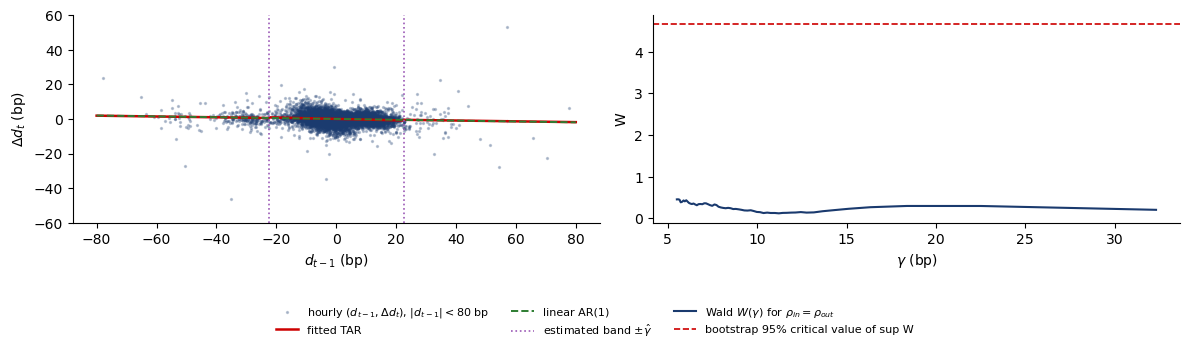

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
m = np.abs(x_) < 80
ax[0].scatter(x_[m], y_[m], s=2, color=BLUE, alpha=0.25, label=r'hourly $(d_{t-1}, \Delta d_t)$, $|d_{t-1}| < 80$ bp')
xx = np.linspace(-80, 80, 400)
ax[0].plot(xx, bh[0] + np.where(np.abs(xx) <= gh, bh[1], bh[2]) * xx, color=RED, lw=1.8, label='fitted TAR')
ax[0].plot(xx, b0[0] + b0[1] * xx, color=GREEN, ls='--', lw=1.4, label='linear AR(1)')
for g in (gh, -gh):
    ax[0].axvline(g, color=ETH, ls=':', lw=1.2, label=(r'estimated band $\pm\hat\gamma$' if g > 0 else None))
ax[0].set_xlabel(r'$d_{t-1}$ (bp)'); ax[0].set_ylabel(r'$\Delta d_t$ (bp)'); ax[0].set_ylim(-60, 60)
ax[1].plot(grid, W, color=BLUE, label=r'Wald $W(\gamma)$ for $\rho_{in} = \rho_{out}$')
ax[1].axhline(crit95, color=RED, ls='--', lw=1.2, label='bootstrap 95% critical value of sup W')
ax[1].set_xlabel(r'$\gamma$ (bp)'); ax[1].set_ylabel('W')
save(fig, 'ba_l5_tar', 0.17, ncol=3)

## Key numbers

In [8]:
inn = np.abs(x_) <= gh
print(f'n = {n} consecutive hourly pairs; estimated threshold gamma = {gh:.1f} bp; share of hours inside the band = {100 * inn.mean():.1f}%')
print(f'sup W = {supW:.2f}; bootstrap 95% critical value = {crit95:.2f}; bootstrap p-value = {pboot:.3f} (B = {B})')
pd.DataFrame({'coefficient': [bh[1], bh[2], b0[1]], 'SE (HC)': [se[1], se[2], np.nan],
              'half-life (hours)': [hl(bh[1]), hl(bh[2]), hl(b0[1])]},
             index=['rho_in (inside the band)', 'rho_out (outside the band)', 'rho, linear AR(1)']).round(4)

n = 40545 consecutive hourly pairs; estimated threshold gamma = 22.5 bp; share of hours inside the band = 99.0%
sup W = 0.46; bootstrap 95% critical value = 4.65; bootstrap p-value = 0.653 (B = 199)


,coefficient,SE (HC),half-life (hours)
rho_in (inside the band),-0.0396,0.0020,17.1663
rho_out (outside the band),-0.0233,0.0297,29.3609
"rho, linear AR(1)",-0.0245,NaN,27.9612


**How to read it:** the slopes are small (about $-0.04$), so reversion is slow at the hourly scale, and the Wald profile never comes close to the bootstrap critical value: there is no threshold effect, and deviations decay in about a day either way.
The large deviations in this sample are the SVB and Terra hours, when redemption was closed or trust was gone; a band model describes normal times, while stress is a change of regime.